# 作业3：NumPy、Matplotlib 与 pandas

学号：2024408029　姓名：何启恒
按顺序运行各代码框。

In [1]:
import hashlib
import os
import platform
import uuid

# 修改为自己的学号
STUDENT_ID = 2024408029

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")


[Conda 环境] None
[学号]       2024408029
[机器指纹] 8c49fe190c554f6a
[RUN_ID]   2024408029-8c49fe190c554f6a


## 一、围绕半圆定律（Wigner 矩阵）

构造 n×n 对称随机矩阵 Z：对所有 1 ≤ i ≤ j ≤ n，独立地从均值为 0、方差为 1/n 的正态分布抽取 Z_ij，再令 Z_ji = Z_ij。其特征值的标准化直方图随 n 增大趋近半圆定律：

f(x) = sqrt(4 - x²) / (2π)，|x| ≤ 2；否则为 0。

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 配置中文字体，避免图中中文显示为方块
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Noto Sans SC"]
plt.rcParams["axes.unicode_minus"] = False

# 固定随机种子，保证结果可复现
rng = np.random.default_rng(2024408029)


In [3]:
def wigner_density(x):
    """返回半圆密度在 x 处的值。

    同时适用于 Python / NumPy 的整数、浮点数；平方根使用 numpy.sqrt。
    """
    x = np.asarray(x)
    inside = np.abs(x) <= 2
    density = np.zeros_like(x, dtype=float)
    density[inside] = np.sqrt(4.0 - x[inside] ** 2) / (2.0 * np.pi)
    return density


In [4]:
def generate_wigner(n):
    """生成 n×n 的 Wigner 对称随机矩阵。

    上三角元素独立服从 N(0, 1/n)，下三角由对称关系 Z_ji = Z_ij 得到。
    输入不是正整数时抛出 ValueError / TypeError。
    """
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)):
        raise TypeError("n 必须是正整数")
    if n <= 0:
        raise ValueError("n 必须是正数")

    scale = 1.0 / np.sqrt(n)
    upper = rng.normal(loc=0.0, scale=scale, size=(n, n))
    # 只保留上三角（含对角线），对称化得到 Wigner 矩阵
    upper = np.triu(upper)
    matrix = upper + upper.T - np.diag(np.diag(upper))
    return matrix


In [5]:
def get_spectrum(matrix):
    """返回矩阵全部特征值组成的 NumPy 数组，按非递减顺序排列。"""
    eigenvalues = np.linalg.eigvalsh(matrix)
    return np.sort(eigenvalues)


In [6]:
# 小例子验证：n=5 的 Wigner 矩阵及其特征值
demo_matrix = generate_wigner(5)
demo_spectrum = get_spectrum(demo_matrix)
print("5×5 Wigner 矩阵：")
print(np.round(demo_matrix, 4))
print("特征值（非递减）：")
print(np.round(demo_spectrum, 4))


5×5 Wigner 矩阵：
[[-0.0575 -0.7238 -0.2252 -0.2916 -0.5454]
 [-0.7238 -0.2522 -0.2516 -0.21    0.2141]
 [-0.2252 -0.2516  0.1973 -0.9874 -0.6861]
 [-0.2916 -0.21   -0.9874 -0.1554  1.4434]
 [-0.5454  0.2141 -0.6861  1.4434  0.1254]]
特征值（非递减）：
[-1.6337 -1.1377 -0.2235  0.607   2.2456]


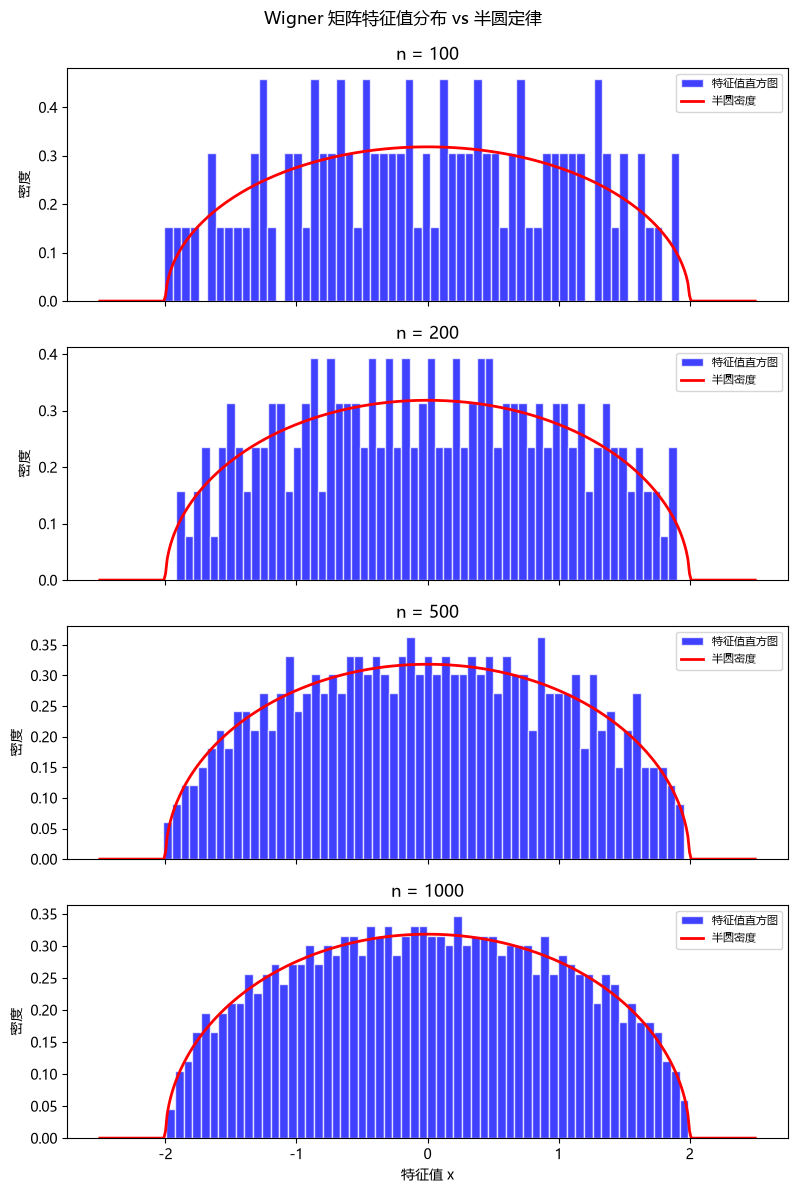

In [7]:
# 画四个纵向排列的子图：n = 100, 200, 500, 1000
fig, axes = plt.subplots(4, 1, figsize=(8, 12), sharex=True)
ns = [100, 200, 500, 1000]
x_curve = np.linspace(-2.5, 2.5, 400)

for ax, n in zip(axes, ns):
    wigner = generate_wigner(n)
    spectrum = get_spectrum(wigner)

    # 标准化直方图：密度=True 使纵轴为概率密度
    ax.hist(spectrum, bins=60, density=True, color="blue",
            edgecolor="white", alpha=0.75, label="特征值直方图")
    # 叠加红色半圆密度曲线
    ax.plot(x_curve, wigner_density(x_curve), color="red",
            linewidth=2, label="半圆密度")
    ax.set_title(f"n = {n}")
    ax.set_ylabel("密度")
    ax.legend(fontsize=8)

axes[-1].set_xlabel("特征值 x")
fig.suptitle("Wigner 矩阵特征值分布 vs 半圆定律", y=0.99)
fig.tight_layout()
plt.savefig("wigner_semicircle.png", dpi=150, bbox_inches="tight")
plt.show()


**观察结论**：n=100、200 时直方图的峰形和两端尾部已经接近半圆，但局部起伏仍较明显；当 n 达到约 500 时，直方图与红色半圆密度曲线已经贴合得比较好，轮廓、峰值和两端衰减都趋于一致；n=1000 时拟合效果进一步稳定。因此从直观图形判断，**n 大约达到 500 左右时半圆密度能较好地拟合特征值分布**，n 继续增大时偏差进一步减小。

（可选：可用 Kolmogorov–Smirnov 检验比较标准化样本与半圆分布的经验分布函数，但半圆分布不是标准连续分布，需要自行构造其 CDF 进行比较。）

## 二、Conway 的生命游戏

棋盘用 NumPy 二维数组表示：活细胞为 1，死细胞为 0。八个邻居（上下左右 + 四个对角），棋盘采用环绕（toroidal）边界。每一步同时更新，计算下一状态时使用原棋盘的邻居状态。

In [8]:
def is_valid_board(board):
    """判断是否为有效的生命游戏棋盘：二维且元素仅为 0 或 1。"""
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    if board.size == 0:
        return False
    return bool(np.all((board == 0) | (board == 1)))


In [9]:
def gol_step(board):
    """返回棋盘下一步的状态；无效输入抛出 ValueError / TypeError。"""
    if not isinstance(board, np.ndarray):
        raise TypeError("board 必须是 NumPy 二维数组")
    if not is_valid_board(board):
        raise ValueError("无效棋盘：必须为二维 0/1 数组")

    # 环绕边界：对原棋盘上下、左右各平移一圈后叠加，得到每个细胞的邻居活细胞数
    neighbors = (
        np.roll(board, shift=1, axis=0) + np.roll(board, shift=-1, axis=0)
        + np.roll(board, shift=1, axis=1) + np.roll(board, shift=-1, axis=1)
        + np.roll(np.roll(board, 1, axis=0), 1, axis=1)
        + np.roll(np.roll(board, 1, axis=0), -1, axis=1)
        + np.roll(np.roll(board, -1, axis=0), 1, axis=1)
        + np.roll(np.roll(board, -1, axis=0), -1, axis=1)
    )

    next_board = np.zeros_like(board)
    # 活细胞：2 或 3 个活邻居存活
    survive = (board == 1) & ((neighbors == 2) | (neighbors == 3))
    # 死细胞：恰好 3 个活邻居复活
    birth = (board == 0) & (neighbors == 3)
    next_board[survive | birth] = 1
    return next_board


In [10]:
def draw_gol_board(board):
    """把棋盘画成 m×n 个方格：活细胞黑色，死细胞白色；不显示网格线、轴标签和刻度。"""
    if not is_valid_board(board):
        raise ValueError("无效棋盘：必须为二维 0/1 数组")

    fig, ax = plt.subplots(figsize=(board.shape[1] / 2, board.shape[0] / 2))
    cmap = plt.get_cmap("binary")
    ax.imshow(board, cmap=cmap, vmin=0, vmax=1, interpolation="nearest")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    for spine in ax.spines.values():
        spine.set_visible(False)
    return fig, ax


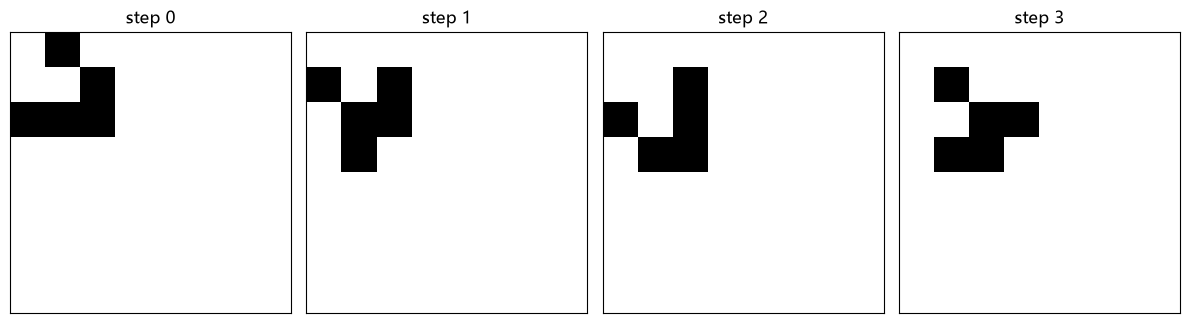

初始棋盘：
[[0 1 0 0 0 0 0 0]
 [0 0 1 0 0 0 0 0]
 [1 1 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]]
第一步后：
[[0 0 0 0 0 0 0 0]
 [1 0 1 0 0 0 0 0]
 [0 1 1 0 0 0 0 0]
 [0 1 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]]


In [11]:
# 演示：一个滑翔机（glider）在 8×8 环绕棋盘上的前 4 步
glider = np.array([
    [0, 1, 0, 0, 0, 0, 0, 0],
    [0, 0, 1, 0, 0, 0, 0, 0],
    [1, 1, 1, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0],
])

fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
current = glider
for step, ax in enumerate(axes):
    ax.imshow(current, cmap="binary", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(f"step {step}")
    ax.set_xticks([])
    ax.set_yticks([])
    current = gol_step(current)
fig.tight_layout()
plt.savefig("gol_glider.png", dpi=150, bbox_inches="tight")
plt.show()

# 验证规则：活细胞邻居数 <2 死亡、>3 死亡；死细胞恰好 3 邻居复活
print("初始棋盘：")
print(glider)
print("第一步后：")
print(gol_step(glider))


## 三、使用 pandas DataFrame

读取群里共享的 Iris.csv（列：Id、SepalLengthCm、SepalWidthCm、PetalLengthCm、PetalWidthCm、Species），修正指定两行，添加花瓣/萼片长宽比特征，保存更正后的 CSV，并按花卉种类分组汇总统计量。

In [12]:
import pandas as pd

# 1. 读入 CSV（第一行为列标题）
iris = pd.read_csv("Iris.csv")

print("数据点数量（行数）：", len(iris))
print("\n列名：", list(iris.columns))
print("\n各列数据类型：")
print(iris.dtypes)
print("\n花卉种类数量：", iris["Species"].nunique())
print("花卉种类：", iris["Species"].unique().tolist())


数据点数量（行数）： 150

列名： ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']

各列数据类型：
Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species              str
dtype: object

花卉种类数量： 3
花卉种类： ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']


In [13]:
# 2. 修正第 35、38 行（0 起始索引 34、37）
# 第 35 行：4.9, 3.1, 1.5, 0.2, "Iris-setosa"（原第四项测量有误）
iris.loc[34, ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm", "Species"]] = \
    [4.9, 3.1, 1.5, 0.2, "Iris-setosa"]

# 第 38 行：4.9, 3.6, 1.4, 0.1, "Iris-setosa"（原第二、三项测量有误）
iris.loc[37, ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm", "Species"]] = \
    [4.9, 3.6, 1.4, 0.1, "Iris-setosa"]

# 检查修改后的两行
print("修改后的索引 34、37：")
print(iris.loc[[34, 37]].to_string())


修改后的索引 34、37：
    Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
34  35            4.9           3.1            1.5           0.2  Iris-setosa
37  38            4.9           3.6            1.4           0.1  Iris-setosa


In [14]:
# 3. 添加两列新特征
# Petal.Ratio：花瓣长度 / 花瓣宽度；Sepal.Ratio：萼片长度 / 萼片宽度
iris["Petal.Ratio"] = iris["PetalLengthCm"] / iris["PetalWidthCm"]
iris["Sepal.Ratio"] = iris["SepalLengthCm"] / iris["SepalWidthCm"]

iris.head()


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Petal.Ratio,Sepal.Ratio
0,1,5.1,3.5,1.4,0.2,Iris-setosa,7.0,1.457143
1,2,4.9,3.0,1.4,0.2,Iris-setosa,7.0,1.633333
2,3,4.7,3.2,1.3,0.2,Iris-setosa,6.5,1.468750
3,4,4.6,3.1,1.5,0.2,Iris-setosa,7.5,1.483871
4,5,5.0,3.6,1.4,0.2,Iris-setosa,7.0,1.388889


In [15]:
# 4. 保存更正并扩展后的 DataFrame
iris.to_csv("iris_corrected.csv", index=False)
print("已保存 iris_corrected.csv")


已保存 iris_corrected.csv


In [16]:
# 5. 按花卉种类分组，计算 Petal.Ratio、Sepal.Ratio 的平均值、中位数、最小值、最大值、标准差
summary = iris.groupby("Species").agg(
    Petal_Ratio_mean=("Petal.Ratio", "mean"),
    Petal_Ratio_median=("Petal.Ratio", "median"),
    Petal_Ratio_min=("Petal.Ratio", "min"),
    Petal_Ratio_max=("Petal.Ratio", "max"),
    Petal_Ratio_std=("Petal.Ratio", "std"),
    Sepal_Ratio_mean=("Sepal.Ratio", "mean"),
    Sepal_Ratio_median=("Sepal.Ratio", "median"),
    Sepal_Ratio_min=("Sepal.Ratio", "min"),
    Sepal_Ratio_max=("Sepal.Ratio", "max"),
    Sepal_Ratio_std=("Sepal.Ratio", "std"),
)
print("按种类分组的长宽比统计量：")
print(summary.round(4).to_string())


按种类分组的长宽比统计量：
                 Petal_Ratio_mean  Petal_Ratio_median  Petal_Ratio_min  Petal_Ratio_max  Petal_Ratio_std  Sepal_Ratio_mean  Sepal_Ratio_median  Sepal_Ratio_min  Sepal_Ratio_max  Sepal_Ratio_std
Species                                                                                                                                                                                          
Iris-setosa                6.9080              7.0000           2.6667             15.0           2.8545            1.4702              1.4631           1.2683           1.9565           0.1187
Iris-versicolor            3.2428              3.2404           2.6667              4.1           0.3125            2.1604              2.1613           1.7647           2.8182           0.2287
Iris-virginica             2.7807              2.6667           2.1250              4.0           0.4074            2.2305              2.1695           1.8235           2.9615           0.2470


### 提交文件清单

- `2024408029_何启恒_hw03.ipynb`：本作业 Notebook；
- `Iris.csv`：群里共享的原始数据集；
- `iris_corrected.csv`：更正并添加特征后的数据集；
- `wigner_semicircle.png`、`gol_glider.png`：作业中生成的图。